# HW2 – 2. Two-stage anchor-based detector (Faster R-CNN)

Faster R-CNN (ResNet-50 FPN, COCO-pretrained) trained under the fixed protocol from notebook 01. Experiments:
1. **Number of RPN proposals × NMS IoU** – grid search at test time on the trained baseline.
2. **Anchor sizes** – default torchvision anchors vs anchors grounded in the object sizes from notebook 01.

The tuned model combines the better training with the best test-time setting. We report mAP, AP50, AP_small and inference speed, measure what each stage contributes and analyse failure cases.

## 0. Setup

In [1]:
# Make the repo importable: Kaggle clones it, locally the root is the parent of notebooks/
import os, sys
from pathlib import Path
if os.path.exists("/kaggle/working"):
    if not os.path.exists("/kaggle/working/repo"):
        !git clone --depth 1 https://github.com/BohdanZasymovych/ai-hw2-object-detection.git /kaggle/working/repo
    !pip install -q pycocotools huggingface_hub   # only if missing; torch/torchvision stay Kaggle's own CUDA builds
    ROOT_DIR = Path("/kaggle/working/repo")
else:
    ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

In [2]:
# Live reload of utils/common.py when editing locally (Kaggle's IPython autoreload is broken on Python 3.13)
if not os.path.exists("/kaggle/working"):
    %load_ext autoreload
    %autoreload 2
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from utils.common import *

seed_everything()
print(env_info(), "| data:", RAW_DIR)

{'python': '3.14.4', 'torch': '2.15.0+cu132', 'torchvision': '0.29.2+cu132', 'gpu': 'cpu', 'on_kaggle': False} | data: /home/bohdan/code/ai/hw2-object-detection/data/raw


Stages run in this session are listed in `RUN`; finished stages are downloaded from the Hugging Face repo, so the notebook can be split over several Kaggle sessions (V1: `baseline`, `grid`; V2: `anchors`, `final`). `QUICK=True` is a local smoke test on a few frames.

In [3]:
RUN = set() # {"baseline", "grid", "anchors", "final"} stages computed in this session; the rest are pulled from the HF repo
QUICK = False                                      # True: local smoke test (few frames, 1 epoch, small input, nothing pushed)

# Fail early if trained stages could not be uploaded (needs HF_TOKEN with write access)
if RUN and not QUICK:
    check_hf_write()

## 1. Training setup

- **Model:** Faster R-CNN ResNet-50 FPN, COCO weights, new 9-way box head (8 classes + background); trainable backbone stages: torchvision default (3).
- **Data:** `PREP` protocol – every 3rd frame (8,090 train / 951 val), 1280 px long side, flip + scale jitter + colour jitter.
- **Optimisation:** SGD (momentum 0.9, weight decay 1e-4), lr 0.005 (linear scaling of torchvision's 0.02 for batch 16 to batch 4), ×0.1 after epoch 2, 3 epochs, AMP, gradient clipping 10. Same seed and budget for every training.
- **Evaluation:** COCO metrics on val after every epoch (best epoch kept), ignore regions as `iscrowd`, up to 300 detections, score ≥ 0.001; speed at batch size 1 with AMP.

In [4]:
CFG = dict(
    epochs=1 if QUICK else 3, batch_size=2 if QUICK else 4, lr=0.005, momentum=0.9, weight_decay=1e-4, lr_drop_epoch=2,
    long_side=640 if QUICK else PREP["long_side"], train_frames=16 if QUICK else None, val_frames=8 if QUICK else None,
    num_workers=4, time_budget_min=90, seed=SEED,
)
DEFAULT_ANCHORS = (32, 64, 128, 256, 512)       # torchvision default, one size per FPN level (P2-P6)
DATA_ANCHORS = (16, 32, 64, 128, 256)           # grounded in the object sizes (notebook 01, section 2.5)
DEFAULT_TEST = dict(proposals=1000, nms=0.5)    # torchvision test-time defaults
GRID = dict(proposals=[300, 1000, 2000], nms=[0.4, 0.5, 0.6])


def name(stage):
    return f"frcnn_{stage}" + ("_quick" if QUICK else "")


print(CFG)

{'epochs': 3, 'batch_size': 4, 'lr': 0.005, 'momentum': 0.9, 'weight_decay': 0.0001, 'lr_drop_epoch': 2, 'long_side': 1280, 'train_frames': None, 'val_frames': None, 'num_workers': 4, 'time_budget_min': 90, 'seed': 42}


## 2. Model and helpers

In [5]:
def build_frcnn(anchor_sizes=DEFAULT_ANCHORS):
    """COCO-pretrained Faster R-CNN R50-FPN with an 8-class head, our input size, evaluation limits and given anchor sizes."""
    m = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1, box_score_thresh=0.001,
                                box_detections_per_img=EVAL_DETS, **tv_size_kwargs(CFG["long_side"]))
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, len(CLASSES) + 1)
    # 3 anchors per location as before, so the pretrained RPN head still fits
    m.rpn.anchor_generator = AnchorGenerator(tuple((s,) for s in anchor_sizes), ((0.5, 1.0, 2.0),) * len(anchor_sizes))
    return m


def set_test_params(m, proposals, nms):
    """Test-time RPN proposals kept after NMS and the IoU of the final per-class NMS."""
    m.rpn._pre_nms_top_n["testing"] = max(1000, proposals)
    m.rpn._post_nms_top_n["testing"] = proposals
    m.roi_heads.nms_thresh = nms
    return m


def ensure_run(stage, weights=False):
    """Local folder of a finished stage; downloaded from the HF repo if it was produced in another session."""
    d = RUNS_DIR / name(stage)
    if not (d / "metrics.json").exists() or (weights and not (d / "best.pt").exists()):
        pull_run(name(stage), weights=weights)
    if not (d / "metrics.json").exists():
        raise FileNotFoundError(f"Stage '{stage}' has no results locally or in the HF repo {HF_REPO}: "
                                f"add '{stage}' to RUN to compute it in this session (RUN = {RUN}).")
    return d


def load_model(stage, anchor_sizes):
    m = build_frcnn(anchor_sizes)
    m.load_state_dict(torch.load(ensure_run(stage, weights=True) / "best.pt", map_location="cpu"))
    return m.to(DEVICE).eval()


def evaluate(model, **kw):
    return evaluate_model(torchvision_predictor(model), "val", max_frames=CFG["val_frames"], batch_size=1,
                          num_workers=CFG["num_workers"], **kw)

In [6]:
def train_stage(stage, anchor_sizes):
    """Train one configuration under the fixed protocol, keep the best epoch, save and upload the run."""
    seed_everything()
    d = run_dir(name(stage))
    model = build_frcnn(anchor_sizes).to(DEVICE)
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=CFG["lr"],
                          momentum=CFG["momentum"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.MultiStepLR(opt, [CFG["lr_drop_epoch"]], 0.1)
    loader = make_loader(DetDataset("train", train=True, max_frames=CFG["train_frames"]), CFG["batch_size"],
                         num_workers=CFG["num_workers"])
    history = fit(model, loader, opt, CFG["epochs"], scheduler=sched, eval_fn=lambda: evaluate(model),
                  ckpt_path=d / "best.pt", last_path=d / "last.pt", resume_from=d / "last.pt",
                  time_budget_s=CFG["time_budget_min"] * 60)
    model.load_state_dict(torch.load(d / "best.pt", map_location=DEVICE))
    metrics = evaluate(model)
    save_run(name(stage), config={**CFG, "anchors": anchor_sizes, "test": DEFAULT_TEST}, history=history, metrics=metrics)
    if not QUICK:
        push_run(name(stage))
    return metrics

In [7]:
@torch.inference_mode()
def rpn_recall(model, ds, ns=(100, 300, 1000, 2000), iou_thr=0.5):
    """Class-agnostic recall of the top-n RPN proposals (IoU >= 0.5), overall and by COCO size."""
    old = model.rpn._pre_nms_top_n["testing"], model.rpn._post_nms_top_n["testing"]
    model.rpn._pre_nms_top_n["testing"] = model.rpn._post_nms_top_n["testing"] = max(ns)
    rows = []
    for images, targets in make_loader(ds, 1, False, CFG["num_workers"]):
        im, t = images[0].to(DEVICE), targets[0]
        if len(t["boxes"]) == 0:
            continue
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            il, _ = model.transform([im])
            props, _ = model.rpn(il, model.backbone(il.tensors))      # sorted by objectness
        h, w = il.image_sizes[0]
        p = props[0].float() * torch.tensor([im.shape[2] / w, im.shape[1] / h] * 2, device=DEVICE)
        iou = box_iou(t["boxes"].to(DEVICE), p)
        b, (sx, sy) = t["boxes"], t["scale"]
        size = (((b[:, 2] - b[:, 0]) / sx) * ((b[:, 3] - b[:, 1]) / sy)).sqrt().numpy()
        hit = {f"top {n}": (iou[:, :n].max(1).values >= iou_thr).cpu().numpy() for n in ns}
        rows.append(pd.DataFrame({"size": size, **hit}))
    model.rpn._pre_nms_top_n["testing"], model.rpn._post_nms_top_n["testing"] = old
    df = pd.concat(rows)
    df["bucket"] = pd.cut(df["size"], [0, 32, 96, 1e9], labels=["small", "medium", "large"])
    out = df.drop(columns="size").groupby("bucket", observed=False).mean()
    out.loc["all"] = df.drop(columns=["size", "bucket"]).mean()
    return out

In [8]:
def match_errors(preds, image_ids, split="val", score_thr=0.3, iou_thr=0.5):
    """Error types at a fixed score threshold.
    GT boxes: correct | crowded (overlapped only by a same-class box already matched to a neighbour) |
              wrong_class (overlapped only by another class) | mislocalized (best IoU 0.1-0.5) | missed.
    Detections: tp | duplicate | wrong_class | ignored (centre in an ignore region) | background."""
    _, boxes, ignore = load_split(split)
    P = pd.DataFrame(preds)
    P = P[P.score >= score_thr]
    bg, ig, pg = boxes.groupby("image_id"), ignore.groupby("image_id"), P.groupby("image_id")
    xyxy = lambda a: torch.tensor(np.c_[a[:, 0], a[:, 1], a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]], dtype=torch.float32)
    gts, dets = [], []
    for i in image_ids:
        g = bg.get_group(i) if i in bg.groups else boxes.iloc[:0]
        p = pg.get_group(i).sort_values("score", ascending=False) if i in pg.groups else P.iloc[:0]
        G = xyxy(g[["x", "y", "w", "h"]].to_numpy(np.float32))
        D = xyxy(np.array(p.bbox.tolist(), np.float32).reshape(-1, 4))
        iou = box_iou(G, D) if len(G) and len(D) else torch.zeros(len(G), len(D))
        gc, dc = g.category_id.to_numpy(), p.category_id.to_numpy()
        matched, dtype = np.zeros(len(G), bool), []
        for k in range(len(D)):
            ov = (iou[:, k] >= iou_thr).numpy()
            same = ov & (gc == dc[k])
            if (same & ~matched).any():
                matched[np.argmax(iou[:, k].numpy() * (same & ~matched))] = True
                dtype.append("tp")
            elif same.any():
                dtype.append("duplicate")
            elif ov.any():
                dtype.append("wrong_class")
            else:
                cx, cy = float(D[k, 0] + D[k, 2]) / 2, float(D[k, 1] + D[k, 3]) / 2
                r = ig.get_group(i) if i in ig.groups else ignore.iloc[:0]
                inside = ((r.x <= cx) & (cx <= r.x + r.w) & (r.y <= cy) & (cy <= r.y + r.h)).any()
                dtype.append("ignored" if inside else "background")
        best = iou.max(1).values.numpy() if len(D) else np.zeros(len(G))
        arg = iou.argmax(1).numpy() if len(D) else np.zeros(len(G), int)
        pred_cls = np.array([CLASSES[dc[a] - 1] if len(D) else None for a in arg], dtype=object)
        overlap = np.where(pred_cls == g.cls.to_numpy(), "crowded", "wrong_class")
        out = np.where(matched, "correct", np.where(best >= iou_thr, overlap, np.where(best >= 0.1, "mislocalized", "missed")))
        gts.append(pd.DataFrame({"image_id": i, "cls": g.cls.to_numpy(), "size": g["size"].to_numpy(),
                                 "occlusion": g.occlusion.to_numpy(), "outcome": out, "pred_cls": pred_cls}))
        dets.append(pd.DataFrame({"image_id": i, "score": p.score.to_numpy(), "outcome": dtype}))
    gt = pd.concat(gts, ignore_index=True)
    gt["bucket"] = pd.cut(gt["size"], [0, 32, 96, 1e9], labels=["small", "medium", "large"])
    return gt, pd.concat(dets, ignore_index=True)

## 3. Speed test

Time per training iteration (including data loading), inference latency and GPU memory, to check that the epochs fit the budget.

In [9]:
if RUN & {"baseline", "anchors"}:
    seed_everything()
    m = build_frcnn().to(DEVICE)
    opt = torch.optim.SGD([p for p in m.parameters() if p.requires_grad], lr=CFG["lr"], momentum=0.9)
    n = 8 if QUICK else 48
    torch.cuda.reset_peak_memory_stats() if DEVICE.type == "cuda" else None
    h = fit(m, make_loader(DetDataset("train", train=True, max_frames=n), CFG["batch_size"], num_workers=CFG["num_workers"]), opt, 1)
    sec_per_img = h[0]["time_s"] / n
    inf = evaluate_model(torchvision_predictor(m), "val", max_frames=20, batch_size=1, num_workers=CFG["num_workers"])
    n_train = len(DetDataset("train", max_frames=CFG["train_frames"]))
    n_val = len(DetDataset("val", max_frames=CFG["val_frames"]))
    epoch_min = (sec_per_img * n_train + inf["ms_per_img"] / 1000 * 1.5 * n_val) / 60   # train + val (x1.5 for loading/COCOeval)
    print(f"train {sec_per_img:.2f} s/img | inference {inf['ms_per_img']:.0f} ms/img | "
          f"peak memory {torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == 'cuda' else 0:.1f} GB")
    print(f"estimated epoch incl. validation: {epoch_min:.0f} min -> run of {CFG['epochs']} epochs: {epoch_min * CFG['epochs']:.0f} min")
    del m, opt
    torch.cuda.empty_cache()

## 4. Baseline

Torchvision defaults: anchors 32–512 px, 1000 test proposals, NMS IoU 0.5.

In [10]:
if "baseline" in RUN:
    train_stage("baseline", DEFAULT_ANCHORS)
base = json.load(open(ensure_run("baseline") / "metrics.json"))
pd.Series({k: v for k, v in base.items() if k != "per_class"}).round(3).to_frame("baseline").T

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,ms_per_img
baseline,0.176,0.369,0.15,0.079,0.166,0.348,0.402,75.947


## 5. Experiment 1 – RPN proposals × NMS IoU

Full 3×3 grid on the trained baseline: number of proposals passed to the second stage and IoU of the final NMS. Both act at test time, so no retraining is needed. Settings are selected on val; the leaderboard is the independent check.

In [11]:
if "grid" in RUN:
    model = load_model("baseline", DEFAULT_ANCHORS)
    rows = []
    for p in GRID["proposals"]:
        for t in GRID["nms"]:
            m = evaluate(set_test_params(model, p, t))
            rows.append({"proposals": p, "nms": t, **{k: v for k, v in m.items() if k != "per_class"}})
    grid = pd.DataFrame(rows)
    best = grid.loc[grid.mAP.idxmax()].to_dict()
    d = save_run(name("grid"), config={"model": name("baseline"), "grid": GRID}, metrics=best)
    grid.to_csv(d / "grid.csv", index=False)
    if not QUICK:
        push_run(name("grid"))
    del model
grid = pd.read_csv(ensure_run("grid") / "grid.csv")
BEST_TEST = dict(proposals=int(grid.loc[grid.mAP.idxmax(), "proposals"]), nms=float(grid.loc[grid.mAP.idxmax(), "nms"]))
print("best test-time setting:", BEST_TEST)
pd.concat({m: grid.pivot(index="proposals", columns="nms", values=m) for m in ["mAP", "AP_small", "ms_per_img"]}, axis=1).round(3)

best test-time setting: {'proposals': 1000, 'nms': 0.6}


mAP               AP_small               ms_per_img                
nms          0.4    0.5    0.6      0.4    0.5    0.6        0.4     0.5     0.6
proposals                                                                       
300        0.172  0.172  0.172    0.079  0.079  0.079     72.172  72.218  72.467
1000       0.175  0.176  0.176    0.079  0.079  0.079     76.200  76.191  75.797
2000       0.175  0.174  0.171    0.081  0.081  0.081     82.301  82.761  82.478

_Findings: to be written after the run._

## 6. Experiment 2 – Anchor sizes

The RPN labels an anchor positive at IoU ≥ 0.7 with a GT box. Below: how well the anchor shapes of each configuration fit the training boxes (best IoU of each box with any anchor shape, position ignored), at the training resolution.

In [12]:
_, bx, _ = load_split("train")
wh = (bx[["w", "h"]].to_numpy() * (CFG["long_side"] / bx[["width", "height"]].max(axis=1).to_numpy())[:, None])
wh = wh[np.random.default_rng(SEED).choice(len(wh), 100_000, replace=False)]
small = (bx["size"].to_numpy() < 32)[np.random.default_rng(SEED).choice(len(bx), 100_000, replace=False)]


def anchor_fit(sizes, ratios=(0.5, 1.0, 2.0)):
    a = np.array([(s / np.sqrt(r), s * np.sqrt(r)) for s in sizes for r in ratios])     # (w, h), r = h / w
    inter = np.minimum(wh[:, None, 0], a[None, :, 0]) * np.minimum(wh[:, None, 1], a[None, :, 1])
    best = (inter / (wh[:, 0:1] * wh[:, 1:2] + a[:, 0] * a[:, 1] - inter)).max(1)
    return {"median best IoU": np.median(best), "% IoU>=0.5": (best >= .5).mean() * 100, "% IoU>=0.7": (best >= .7).mean() * 100,
            "% IoU>=0.7 (small)": (best[small] >= .7).mean() * 100}


pd.DataFrame({"default 32-512": anchor_fit(DEFAULT_ANCHORS), "data-driven 16-256": anchor_fit(DATA_ANCHORS)}).T.round(2)

,median best IoU,% IoU>=0.5,% IoU>=0.7,% IoU>=0.7 (small)
default 32-512,0.62,72.01,36.35,10.38
data-driven 16-256,0.69,97.74,48.70,49.22


In [13]:
if "anchors" in RUN:
    train_stage("anchors", DATA_ANCHORS)
anch = json.load(open(ensure_run("anchors") / "metrics.json"))
pd.DataFrame({s: {k: v for k, v in m.items() if k != "per_class"} for s, m in [("baseline", base), ("anchors", anch)]}).T.round(3)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,ms_per_img
baseline,0.176,0.369,0.150,0.079,0.166,0.348,0.402,75.947
anchors,0.167,0.359,0.139,0.081,0.165,0.303,0.363,76.044


_Findings: to be written after the run._

## 7. Tuned model and comparison

Tuned model: the better of the two trainings (val mAP) with the best test-time setting from experiment 1. Its val predictions are saved for the analysis below.

In [14]:
if "final" in RUN:
    src, sizes = ("anchors", DATA_ANCHORS) if anch["mAP"] >= base["mAP"] else ("baseline", DEFAULT_ANCHORS)
    model = set_test_params(load_model(src, sizes), **BEST_TEST)
    ds = DetDataset("val", max_frames=CFG["val_frames"])
    preds, ms = predict_dataset(torchvision_predictor(model), ds, batch_size=1, num_workers=CFG["num_workers"])
    metrics = {**coco_evaluate(preds, "val", image_ids=ds.image_ids), "ms_per_img": ms}
    d = save_run(name("final"), config={"trained": name(src), "anchors": sizes, "test": BEST_TEST, "image_ids": ds.image_ids},
                 metrics=metrics, preds=preds)
    rpn_recall(model, ds).to_csv(d / "rpn_recall.csv")
    if not QUICK:
        push_run(name("final"))
    del model
d = ensure_run("final")
final_cfg, final = json.load(open(d / "config.json")), json.load(open(d / "metrics.json"))
preds = json.load(open(d / "preds_val.json"))

cols = ["mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR", "ms_per_img"]
labels = {"baseline": "baseline", "grid": "baseline + best test setting", "anchors": "data-driven anchors", "final": "tuned"}
table = load_results().reindex([name(s) for s in labels])[cols]
table.index = list(labels.values())
print("tuned =", final_cfg["trained"], "+", final_cfg["test"])
table

tuned = frcnn_baseline + {'proposals': 1000, 'nms': 0.6}


,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR,ms_per_img
baseline,0.176,0.369,0.150,0.079,0.166,0.348,0.402,75.947
baseline + best test setting,0.176,0.366,0.151,0.079,0.166,0.347,0.401,75.797
data-driven anchors,0.167,0.359,0.139,0.081,0.165,0.303,0.363,76.044
tuned,0.176,0.366,0.151,0.079,0.166,0.347,0.401,76.323


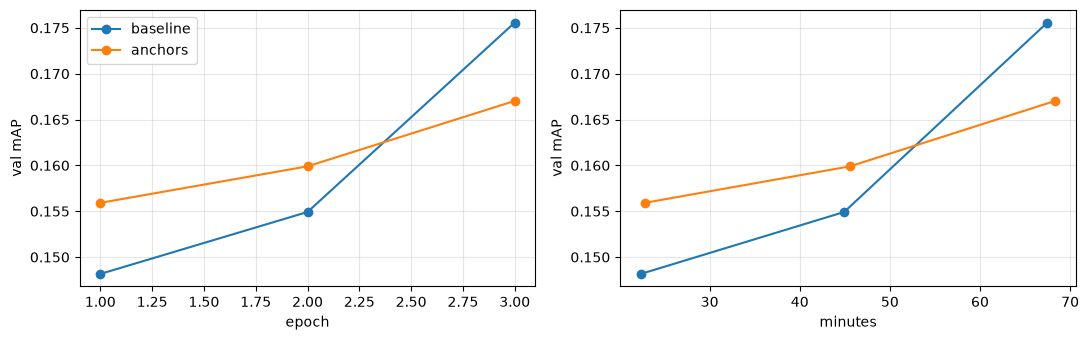

,person,bicycle,car,van,truck,tricycle,bus,motor
baseline,0.216,0.099,0.355,0.189,0.193,0.199,0.085,0.069
tuned,0.219,0.097,0.356,0.186,0.193,0.200,0.087,0.069


In [15]:
# Training curves and per-class AP
plot_history({s: json.load(open(ensure_run(s) / "history.json")) for s in ["baseline", "anchors"]})
pd.DataFrame({"baseline": base["per_class"], "tuned": final["per_class"]}).T.round(3)

_Findings: to be written after the run._

## 8. What each stage contributes

- **RPN (first stage):** class-agnostic objectness on dense anchors; it proposes a few hundred to a few thousand candidate boxes. Its recall is the upper bound for the detector: an object without a proposal cannot be detected.
- **RoI head (second stage):** pools features for each proposal (RoIAlign), classifies it into the 8 classes or background, refines the box and removes duplicates with per-class NMS. It turns high-recall, low-precision proposals into few confident, labelled boxes.

Measured below: recall of the top-n proposals (class-agnostic, IoU ≥ 0.5) against the recall and box count of the final detections.

In [16]:
gt, det = match_errors(preds, final_cfg["image_ids"])
rpn = pd.read_csv(ensure_run("final") / "rpn_recall.csv", index_col=0)
found = gt.outcome.isin(["correct", "crowded", "wrong_class"])                 # GT covered by a final box (IoU >= 0.5, any class)
fin = found.groupby(gt.bucket.astype(str)).mean()
fin["all"] = found.mean()
rpn["final (score>=0.3)"] = fin
print(f"boxes per image: RPN {final_cfg['test']['proposals']} proposals -> final {len(det) / len(final_cfg['image_ids']):.0f} detections (score >= 0.3)")
rpn.round(3)

boxes per image: RPN 1000 proposals -> final 59 detections (score >= 0.3)


,top 100,top 300,top 1000,top 2000,final (score>=0.3)
bucket,,,,,
small,0.479,0.641,0.706,0.706,0.531
medium,0.567,0.716,0.815,0.822,0.672
large,0.802,0.925,0.986,0.989,0.949
all,0.577,0.725,0.813,0.818,0.676


_Findings: to be written after the run._

## 9. Failure cases

Errors of the tuned model at score ≥ 0.3 and IoU 0.5: outcome of every GT box by size and occlusion, class confusions and the types of false positives.

In [17]:
by_size = pd.crosstab(gt.bucket, gt.outcome, normalize="index").mul(100).round(1)
by_occ = pd.crosstab(gt.occlusion, gt.outcome, normalize="index").mul(100).round(1)
confusion = pd.crosstab(gt[gt.outcome == "wrong_class"].cls, gt[gt.outcome == "wrong_class"].pred_cls)
print("GT outcome by size (%):\n", by_size, "\n\nGT outcome by occlusion (%):\n", by_occ)
print("\nclass confusions (GT -> predicted):\n", confusion, "\n\ndetections by type:\n", det.outcome.value_counts().to_string())

GT outcome by size (%):
 outcome  correct  crowded  mislocalized  missed  wrong_class
bucket                                                      
small       45.9      0.6          22.6    24.3          6.6
medium      58.7      0.6          13.6    19.2          7.9
large       81.0      0.1           2.5     2.6         13.7 

GT outcome by occlusion (%):
 outcome    correct  crowded  mislocalized  missed  wrong_class
occlusion                                                     
0.0           73.6      0.3           9.0    10.4          6.8
1.0           52.2      0.5          18.0    19.1         10.1
2.0           18.6      2.5          14.2    61.0          3.7

class confusions (GT -> predicted):
 pred_cls  bicycle  bus  car  motor  person  tricycle  truck  van
cls                                                             
bicycle         0    0    0    631     231        38      0    0
bus             0    0   57      0       0         0      3   13
car             0    1   

Frames with the most missed small objects, the most class confusions and the most background false positives (GT coloured by class, ignore regions red, predictions white).

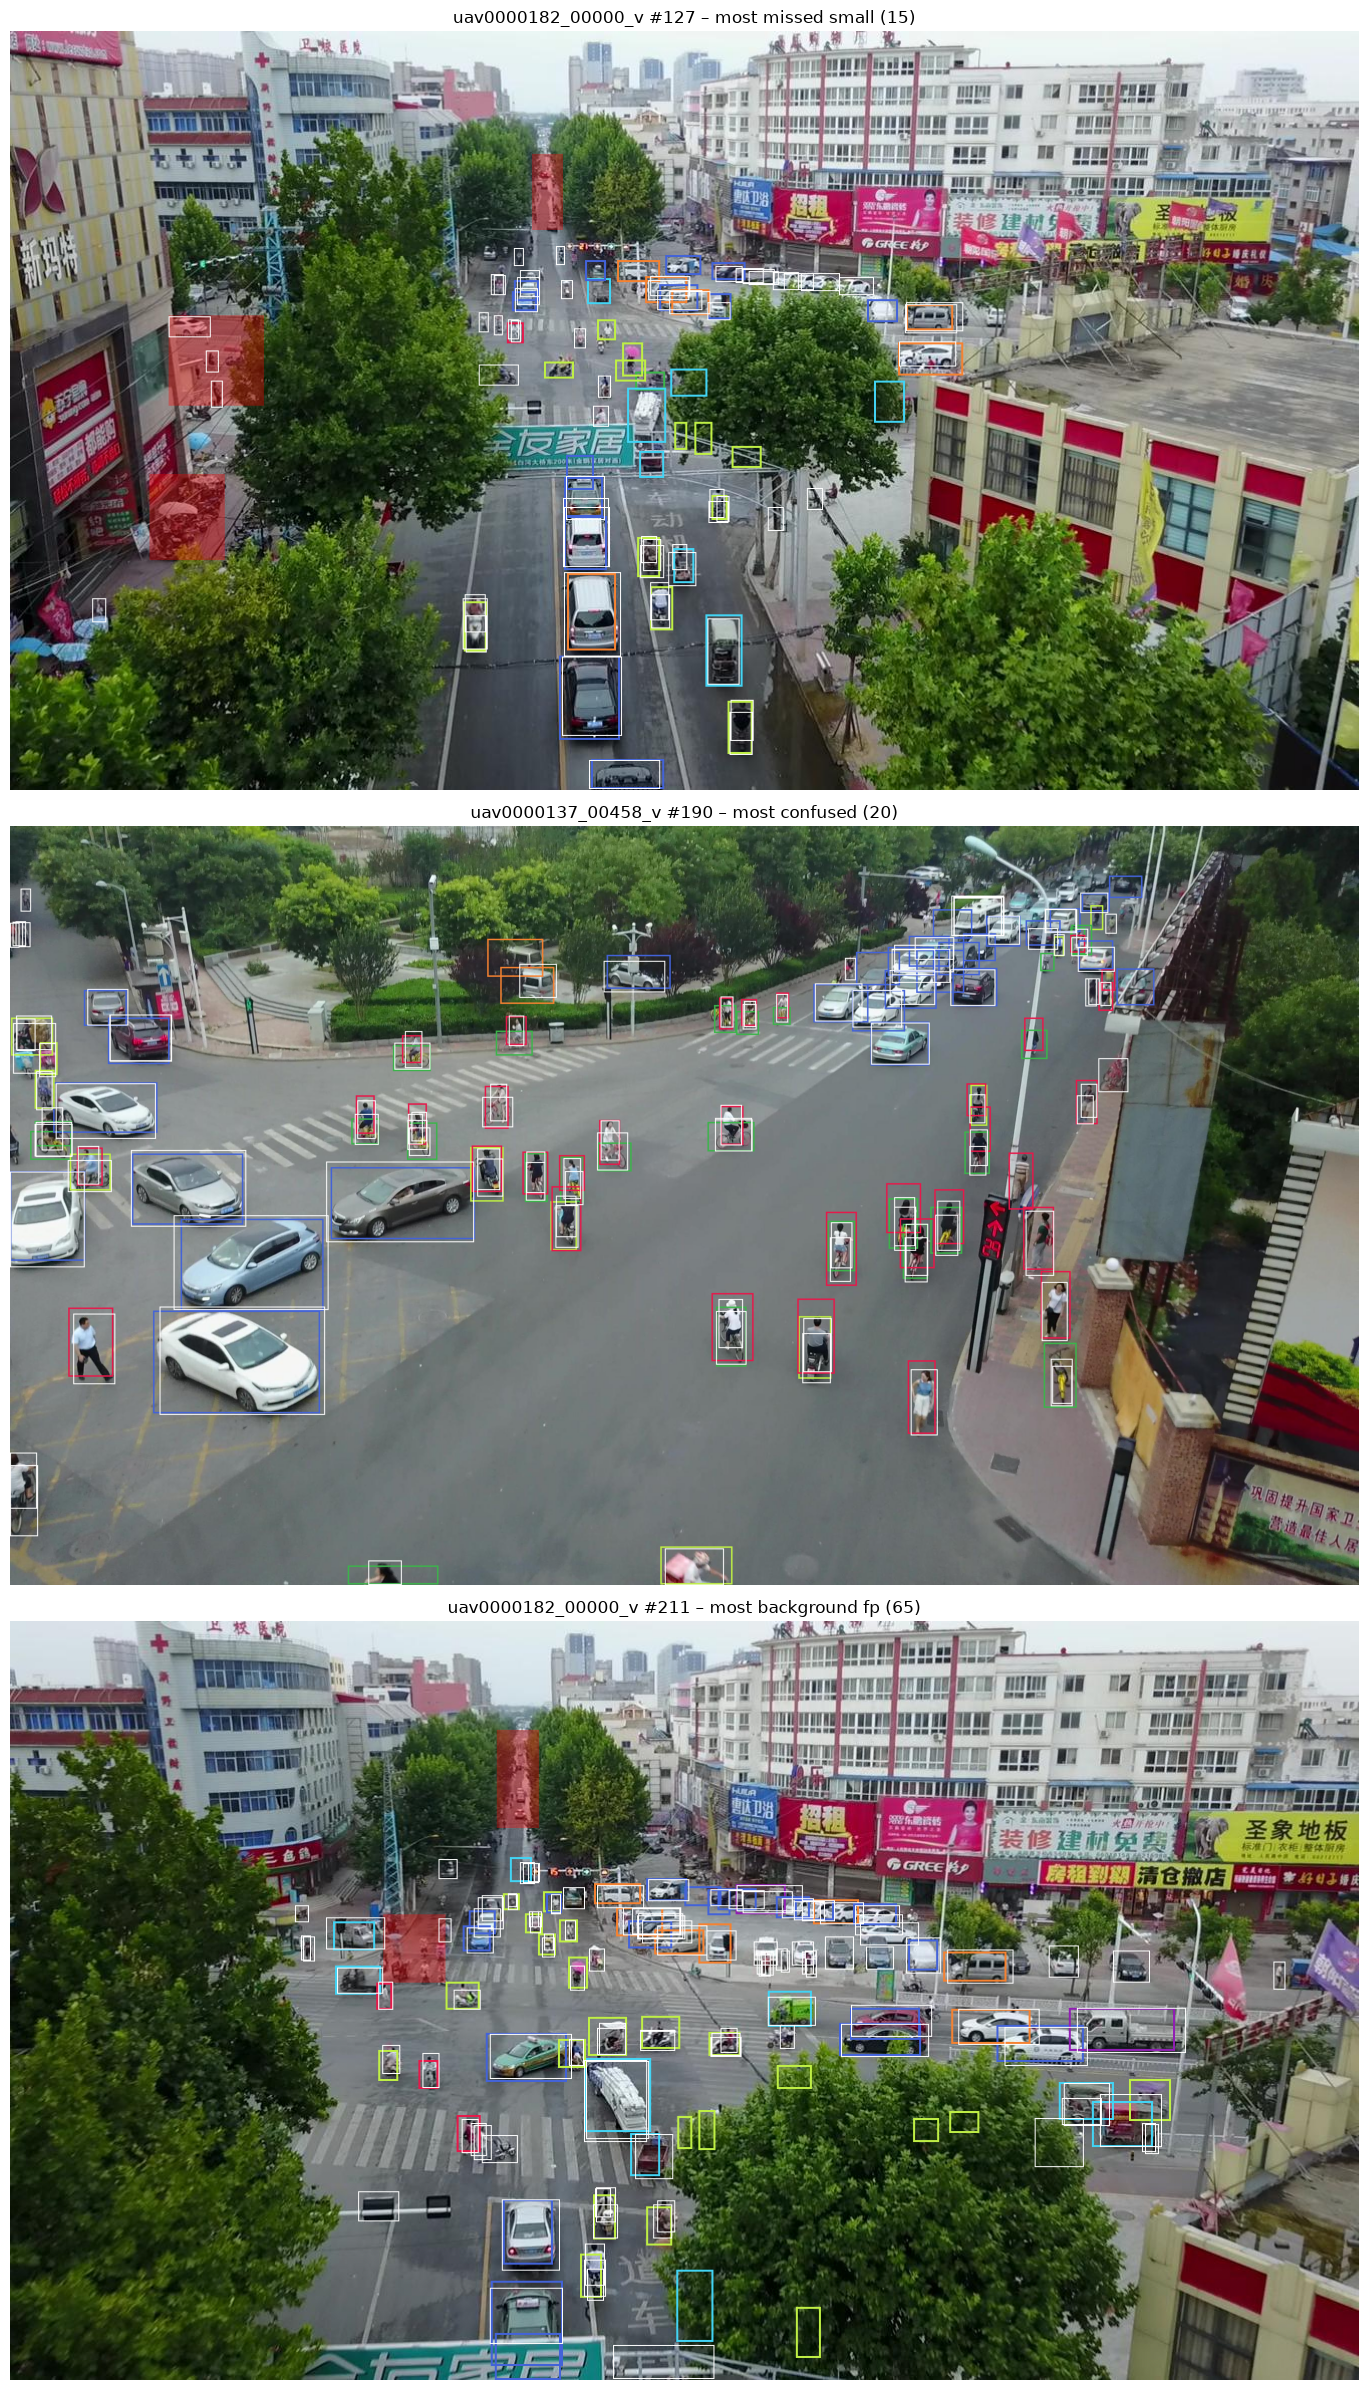

In [18]:
per_img = gt.assign(missed_small=(gt.outcome == "missed") & (gt.bucket == "small"), confused=gt.outcome == "wrong_class") \
    .groupby("image_id")[["missed_small", "confused"]].sum()
per_img["background_fp"] = det[det.outcome == "background"].groupby("image_id").size().reindex(per_img.index, fill_value=0)
picks = {k: per_img[k].idxmax() for k in ["missed_small", "confused", "background_fp"]}
fig, axs = plt.subplots(3, 1, figsize=(14, 24))
for ax, (k, i) in zip(axs, picks.items()):
    draw_frame("val", i, ax, preds=preds, score_thr=0.3)
    ax.set_title(f"{ax.get_title()} – most {k.replace('_', ' ')} ({per_img.loc[i, k]})")
plt.tight_layout(); plt.show()

_Failure cases and their likely causes: to be written after the run._

## 10. Conclusion

_To be written after the run._